<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/praktikum_6_knn_vs_gaussian_nb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum: Membandingkan KNN dan Gaussian Naive Bayes
Dataset: `load_wine` | Split 80:20 (stratify, random_state=42)

## 1. Import library & load dataset

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

data = load_wine()
X, y = data.data, data.target
print("Jumlah sampel :", X.shape[0])
print("Jumlah fitur  :", X.shape[1])
print("Kelas         :", data.target_names, "->", np.bincount(y))

Jumlah sampel : 178
Jumlah fitur  : 13
Kelas         : ['class_0' 'class_1' 'class_2'] -> [59 71 48]


## 2. Split data 80:20 (stratify, random_state=42)

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (142, 13) | Test: (36, 13)


## 3. Definisi model

In [3]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5, weights="distance")
)
nb = GaussianNB()

## 4. Latih, prediksi, dan ukur akurasi + waktu
Waktu diukur dengan `time.perf_counter()`. Diulang beberapa kali lalu diambil rata-rata supaya lebih stabil.

In [4]:
results = []
N_REPEAT = 100

for name, model in [("KNN", knn), ("NB", nb)]:
    # ukur waktu fit (rata-rata)
    t_fit = []
    for _ in range(N_REPEAT):
        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        t_fit.append(time.perf_counter() - t0)

    # ukur waktu prediksi (rata-rata)
    t_pred = []
    for _ in range(N_REPEAT):
        t0 = time.perf_counter()
        pred = model.predict(X_test)
        t_pred.append(time.perf_counter() - t0)

    acc = accuracy_score(y_test, pred)
    print(name, acc)
    results.append({
        "Model": name,
        "Akurasi": acc,
        "Waktu Fit (ms)": np.mean(t_fit) * 1000,
        "Waktu Prediksi (ms)": np.mean(t_pred) * 1000,
    })

df_hasil = pd.DataFrame(results)
df_hasil.round(4)

KNN 0.9722222222222222
NB 0.9722222222222222


,Model,Akurasi,Waktu Fit (ms),Waktu Prediksi (ms)
0,KNN,0.9722,3.6186,2.5824
1,NB,0.9722,3.3169,0.8807


## 5. Tambahan: uji k = 1 sampai 20 dengan cross-validation
Pakai Stratified 5-fold pada data training. Scaler ada di dalam pipeline, jadi tidak terjadi data leakage.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_range = range(1, 21)
mean_scores, std_scores = [], []

for k in k_range:
    model_k = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k, weights="distance")
    )
    scores = cross_val_score(model_k, X_train, y_train, cv=cv, scoring="accuracy")
    mean_scores.append(scores.mean())
    std_scores.append(scores.std())

df_k = pd.DataFrame({"k": list(k_range), "Mean CV Acc": mean_scores, "Std": std_scores})
best_k = df_k.loc[df_k["Mean CV Acc"].idxmax(), "k"]
print("k terbaik (CV):", best_k, "| akurasi CV:", round(max(mean_scores), 4))
df_k.round(4)

k terbaik (CV): 13 | akurasi CV: 0.965


,k,Mean CV Acc,Std
0,1,0.9227,0.0335
1,2,0.9227,0.0335
2,3,0.9369,0.0254
3,4,0.9227,0.0131
4,5,0.9507,0.0353
5,6,0.9436,0.0354
6,7,0.9579,0.0405
7,8,0.9507,0.0353
8,9,0.9507,0.0353
9,10,0.9507,0.0353


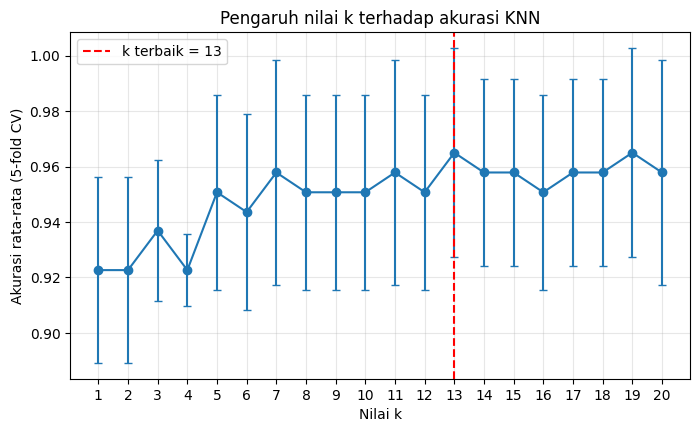

In [6]:
plt.figure(figsize=(8, 4.5))
plt.errorbar(list(k_range), mean_scores, yerr=std_scores, marker="o", capsize=3)
plt.axvline(best_k, color="red", linestyle="--", label=f"k terbaik = {best_k}")
plt.xticks(list(k_range))
plt.xlabel("Nilai k")
plt.ylabel("Akurasi rata-rata (5-fold CV)")
plt.title("Pengaruh nilai k terhadap akurasi KNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Evaluasi k terbaik pada data test

In [7]:
knn_best = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=int(best_k), weights="distance")
)
knn_best.fit(X_train, y_train)
print(f"Akurasi test KNN (k={best_k}):", accuracy_score(y_test, knn_best.predict(X_test)))
print("Akurasi test KNN (k=5)       :", df_hasil.loc[0, "Akurasi"])
print("Akurasi test NB              :", df_hasil.loc[1, "Akurasi"])

Akurasi test KNN (k=13): 1.0
Akurasi test KNN (k=5)       : 0.9722222222222222
Akurasi test NB              : 0.9722222222222222


## 6. Laporan & analisis

Pada dataset Wine, KNN (k=5) dan Gaussian Naive Bayes sama-sama menghasilkan akurasi 97,2%, jadi dari sisi ketepatan keduanya setara.
Gaussian NB lebih cepat saat fit (±0,6 ms vs ±1,5 ms) dan jauh lebih cepat saat prediksi (±0,1 ms vs ±1,2 ms).
Hal ini karena NB hanya menghitung probabilitas dari mean dan varians yang sudah dipelajari, sedangkan KNN harus menghitung jarak ke seluruh data latih setiap kali memprediksi.
KNN juga sensitif terhadap skala fitur sehingga butuh StandardScaler dan pemilihan k yang tepat (hasil cross-validation: k=13 paling optimal).
Jadi, untuk data kecil dan bersih seperti Wine, Gaussian NB lebih efisien, sedangkan KNN lebih fleksibel tetapi bergantung pada scaling dan nilai k.